# Proton Momentum Real Data -- Containment Split

Real-data (10% unblinded Run 2, 2.36e19 POT) counterpart of `proton_momentum/Asimov_Containment_Studies.ipynb`, for the containment-split (contained/exiting) simultaneous fit in the leading proton momentum, $p_p$. It reads the `RealData_Containment` outputs listed in `RunConfigs/proton_momentum/RealData_Containment/RealData_Containment_instructions.md`. The structure follows `muon_angle/RealData_Containment_Studies.ipynb`, with the overflow-bin handling taken from the dpT notebooks.

**Likelihood:** `BarlowLLH` (not `PoissonLLH`), which accounts for the finite MC statistics. This is appropriate now that the data is real and not Asimov.

**Known gap, not introduced here:** `dataSetListConfig_RealData.yaml` does not define `ICARUS_NuMI_1muNp0pi_cosmics` and `_cosmics_sideband` (they are commented out), while the containment fitSampleSet's selection and sideband samples reference them. The same mismatch exists in the dpT, dalphaT, opening-angle and muon-angle real-data configurations, so the proton-momentum setup inherits it.

**Binning:** truth binning is `binning_true_proton_momentum.txt` (8 finite bins from 0.31 to 1.2 GeV/c plus one overflow bin, 9 bins in total, shared across all 4 samples). Reco binning is per channel: contained selection uses `binning_reco_leading_proton_momentum_contained.txt` (17 rows), exiting selection uses `binning_reco_leading_proton_momentum_exiting.txt` (17 rows), and both sidebands use their own 25-row files. Every one of these files ends with an overflow row, so the finite bins are 16, 16, 24 and 24. In the plots the overflow bin is dropped (`remove_last_bin=True`, the default), so the 9 plotted edges give 8 bins.

**`cov_bin_range` -- expected from the dpT convention, NOT YET VERIFIED on a proton-momentum output file.** `covarianceMatrix_TH2D` keeps the overflow row of each sample, so the full matrix is 17 + 17 + 25 + 25 = 84 rows, with block boundaries at 0, 17, 34, 59 and 84. The category histograms drop the overflow row, so each slice stops one row short of its block boundary: (0,16), (17,33), (34,58), (59,83). Run the sanity-check cell below on the real-data prefit file first. If it reports a mismatch, edit the `cov_bin_range` values in the four sample sections.

**Units:** momentum is in GeV/c everywhere (truth binning, GUNDAM output, NUISANCE flat trees), so the cross section is in cm$^2$/((GeV/c) Ar), scaled by $10^{40}$, with no MeV-to-GeV conversion.

**Not included here:** the bespoke mirror-dial systematic studies from `dpT/RealData_Studies.ipynb` (VecFFCCQEshape, DecayAngMEC, Theta_Delta2Npi grid fits and LLH scans) are not ported. They are specialized real-data diagnostics and would need their own adaptation.


In [1]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

## Binning Sanity Check

Compares the expected covariance block widths with the actual contents of the real-data pre-fit toy-generator file. The full matrix has one extra row per sample (the overflow row), so its expected size is the sum of the slice widths plus 4. Every line should end in `OK`.


In [2]:
import uproot

PREFIT_FILE = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/prefit_real_containment_proton_momentum.root'
SAMPLES = {
    'selection_contained': 'selection_reco_proton_momentum_contained',
    'selection_exiting':   'selection_reco_proton_momentum_exiting',
    'sideband_contained':  'sideband_reco_proton_momentum_contained',
    'sideband_exiting':    'sideband_reco_proton_momentum_exiting',
}
COV_RANGE = {
    'selection_contained': (0, 16),
    'selection_exiting':   (17, 33),
    'sideband_contained':  (34, 58),
    'sideband_exiting':    (59, 83),
}

f_pre = uproot.open(PREFIT_FILE)
cov_full = f_pre['toyGen/matrices/covarianceMatrix_TH2D'].values()
# Each block carries one overflow row that the category histograms drop: 80 finite rows + 4 overflow rows = 84.
expected_rows = sum(hi - lo for lo, hi in COV_RANGE.values()) + len(COV_RANGE)
print(f'covarianceMatrix_TH2D shape: {cov_full.shape}  (expected {expected_rows} x {expected_rows})  ->',
      'OK' if cov_full.shape == (expected_rows, expected_rows) else 'MISMATCH')

for key, sample in SAMPLES.items():
    lo, hi = COV_RANGE[key]
    nbins = None
    for cat in range(11):
        path = f'toyGen/plots/histograms/{sample} (pre-fit)/reco_leading_proton_momentum/category/{cat}/MC_TH1D'
        try:
            nbins = len(f_pre[path].values())
            break
        except KeyError:
            continue
    status = 'OK' if nbins == hi - lo else 'MISMATCH'
    print(f'{sample:<36} category-histogram bins: {nbins}  |  COV_RANGE width: {hi - lo}  ->  {status}')


covarianceMatrix_TH2D shape: (84, 84)  (expected 84 x 84)  -> OK
selection_reco_proton_momentum_contained category-histogram bins: 16  |  COV_RANGE width: 16  ->  OK
selection_reco_proton_momentum_exiting category-histogram bins: 16  |  COV_RANGE width: 16  ->  OK
sideband_reco_proton_momentum_contained category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK
sideband_reco_proton_momentum_exiting category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK


## Selection - Contained

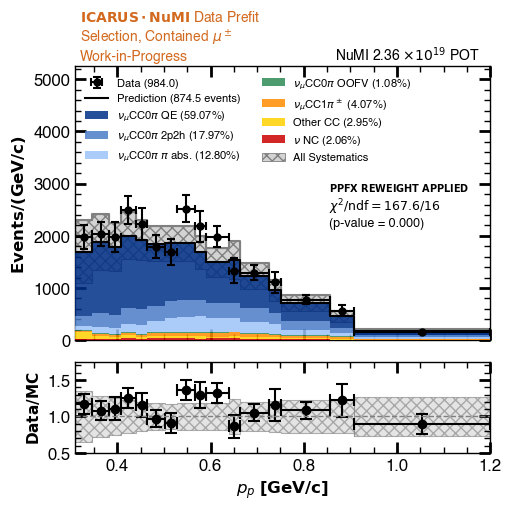

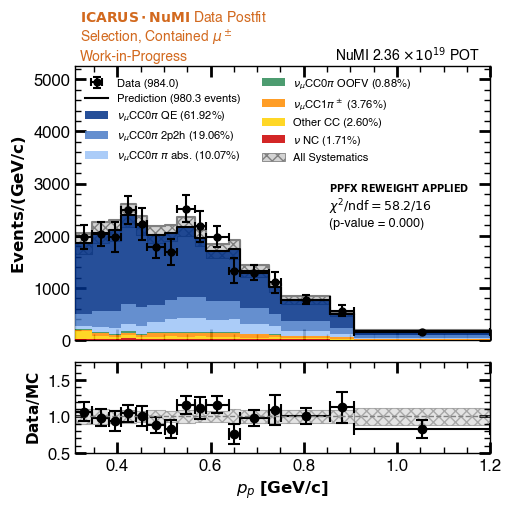

In [3]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/prefit_real_containment_proton_momentum.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    sample_name='selection_reco_proton_momentum_contained',
    is_data=True,
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=(0, 16),  # block [0,17) includes the overflow row in the covariance matrix, but the category histograms drop it, so the slice stops one row short. Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/proton_momentum/RealData_Containment/Prefits', save_name='prefit_proton_momentum_selection_contained',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/postfit_real_containment_proton_momentum.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    sample_name='selection_reco_proton_momentum_contained',
    is_data=True,
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=(0, 16),  # block [0,17) includes the overflow row in the covariance matrix, but the category histograms drop it, so the slice stops one row short. Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/proton_momentum/RealData_Containment/Postfits', save_name='postfit_proton_momentum_selection_contained'
)

## Selection - Exiting

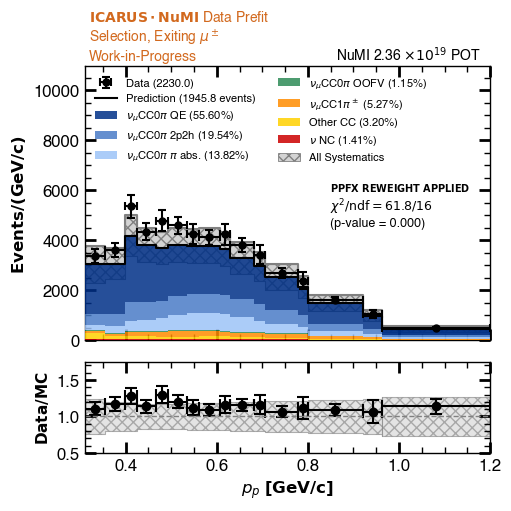

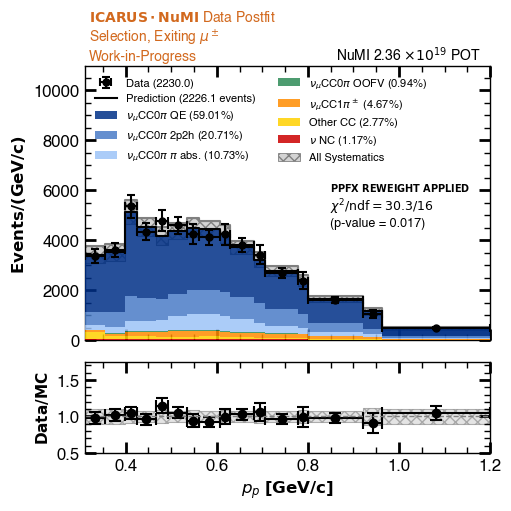

In [4]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/prefit_real_containment_proton_momentum.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    sample_name='selection_reco_proton_momentum_exiting',
    is_data=True,
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=(17, 33),  # block [17,34) includes the overflow row in the covariance matrix, but the category histograms drop it, so the slice stops one row short. Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/proton_momentum/RealData_Containment/Prefits', save_name='prefit_proton_momentum_selection_exiting',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/postfit_real_containment_proton_momentum.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    sample_name='selection_reco_proton_momentum_exiting',
    is_data=True,
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=(17, 33),  # block [17,34) includes the overflow row in the covariance matrix, but the category histograms drop it, so the slice stops one row short. Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/proton_momentum/RealData_Containment/Postfits', save_name='postfit_proton_momentum_selection_exiting'
)

## Sideband - Contained

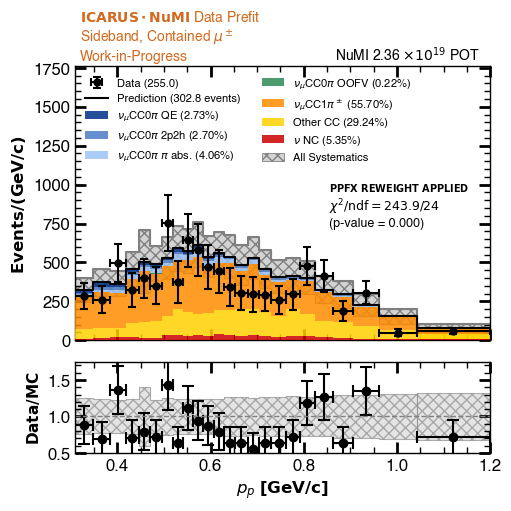

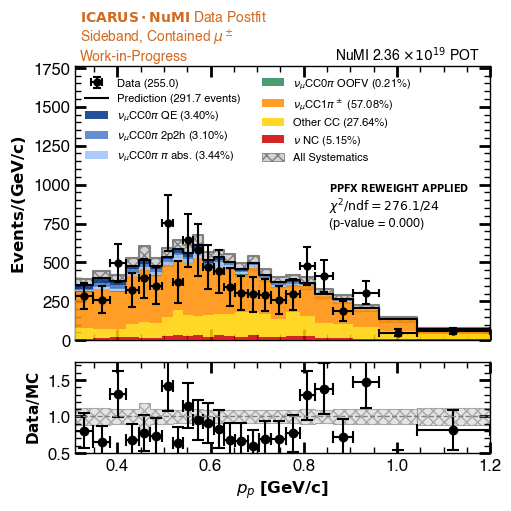

In [5]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/prefit_real_containment_proton_momentum.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    sample_name='sideband_reco_proton_momentum_contained',
    is_data=True,
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=(34, 58),  # block [34,59) includes the overflow row in the covariance matrix, but the category histograms drop it, so the slice stops one row short. Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/proton_momentum/RealData_Containment/Prefits', save_name='prefit_proton_momentum_sideband_contained',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/postfit_real_containment_proton_momentum.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    sample_name='sideband_reco_proton_momentum_contained',
    is_data=True,
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=(34, 58),  # block [34,59) includes the overflow row in the covariance matrix, but the category histograms drop it, so the slice stops one row short. Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/proton_momentum/RealData_Containment/Postfits', save_name='postfit_proton_momentum_sideband_contained'
)

## Sideband - Exiting

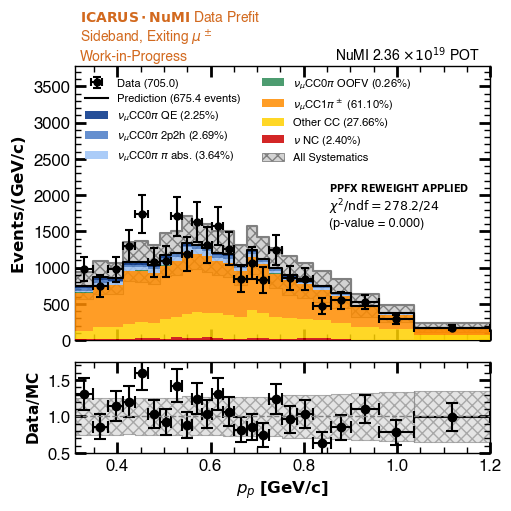

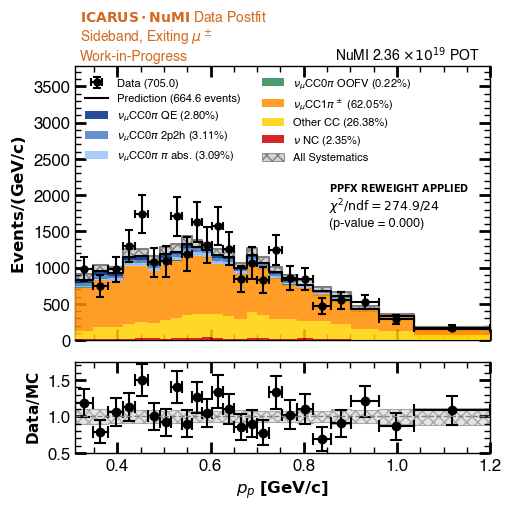

In [6]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/prefit_real_containment_proton_momentum.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    sample_name='sideband_reco_proton_momentum_exiting',
    is_data=True,
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=(59, 83),  # block [59,84) includes the overflow row in the covariance matrix, but the category histograms drop it, so the slice stops one row short. Verify with the sanity-check cell.
    fit_type='pre-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/proton_momentum/RealData_Containment/Prefits', save_name='prefit_proton_momentum_sideband_exiting',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/postfit_real_containment_proton_momentum.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    sample_name='sideband_reco_proton_momentum_exiting',
    is_data=True,
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=(59, 83),  # block [59,84) includes the overflow row in the covariance matrix, but the category histograms drop it, so the slice stops one row short. Verify with the sanity-check cell.
    fit_type='post-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/proton_momentum/RealData_Containment/Postfits', save_name='postfit_proton_momentum_sideband_exiting'
)

## Cross-Section Extraction

Extracted from `real_containment_XSec_proton_momentum.root`. It uses the true-level `True_proton_momentum_XS` sample with 8 finite truth bins plus one overflow bin, which the reco-level containment split does not change. The overflow bin is dropped from the plot, so the 9 edges give 8 plotted bins. The truth binning is in GeV/c, so the units are cm$^2$/((GeV/c) Ar), scaled by $10^{40}$, with no unit conversion. The generator overlays divide by bin width in GeV/c and use the same $10^{40}$ scaling.


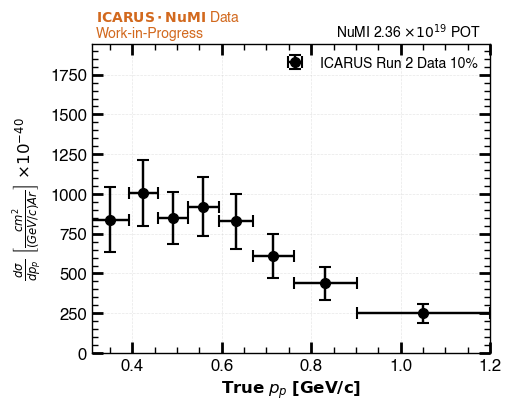

In [7]:
fig_xs, ax_xs, xsec_extracted_raw, xsec_extracted_errors_raw = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/XSection/proton_momentum/RealData_Containment/real_containment_XSec_proton_momentum.root',
        is_cross_section = True,
        hist_path="calcXsec/histograms/True_proton_momentum_XS_TH1D;1",
        xlabel=r'$\mathbf{True}$ $p_{p}$ $\mathbf{[GeV/c]}$',
        ylabel=r'$\frac{d\sigma}{dp_{p}}$ $\left[\frac{cm^2}{(GeV/c)Ar}\right]$ $\times 10^{-40}$',
        bin_edges_labels=[0.31, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.762, 0.9018, 1.2],
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        label="ICARUS Run 2 Data 10%",
        pot=r'NuMI 2.36 $\times 10^{19}$ POT',
        scaling_power_of_10=1e40
)
save_fig(fig_xs, r'../Plots/proton_momentum/RealData_Containment/XSection', 'proton_momentum_XS')


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           8.064178e+02
  0.3927 – 0.4571           8.069495e+02
  0.4571 – 0.5239           7.417047e+02
  0.5239 – 0.5934           7.011902e+02
  0.5934 – 0.6689           6.375049e+02
  0.6689 – 0.7620           5.133252e+02
  0.7620 – 0.9018           3.497182e+02
  0.9018 – 1.2000           1.766751e+02

χ² / Ndof = 6.7 / 8 = 0.833
p-value = 0.573


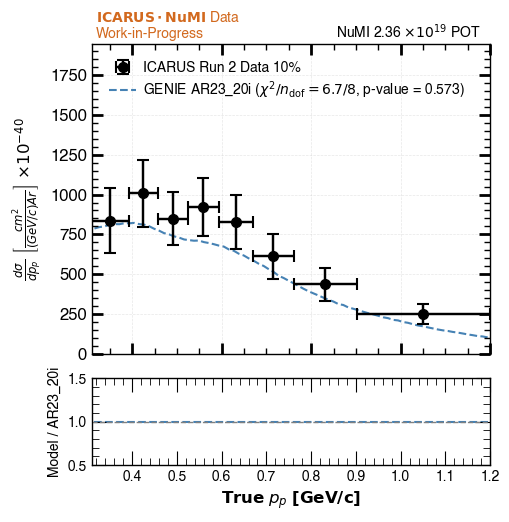

In [8]:
# Overlay GENIE with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14",
    bin_edges           = [0.31, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.762, 0.9018, 1.2],
    nuisance_var        = 'ICARUS_1muNp0pi_ProtonP',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE AR23_20i',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/proton_momentum/RealData_Containment/XSection', 'proton_momentum_XS_wGENIE')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           7.921374e+02
  0.3927 – 0.4571           8.454110e+02
  0.4571 – 0.5239           7.434012e+02
  0.5239 – 0.5934           7.241862e+02
  0.5934 – 0.6689           7.063703e+02
  0.6689 – 0.7620           6.134495e+02
  0.7620 – 0.9018           4.201567e+02
  0.9018 – 1.2000           1.968467e+02

χ² / Ndof = 3.5 / 8 = 0.436
p-value = 0.900


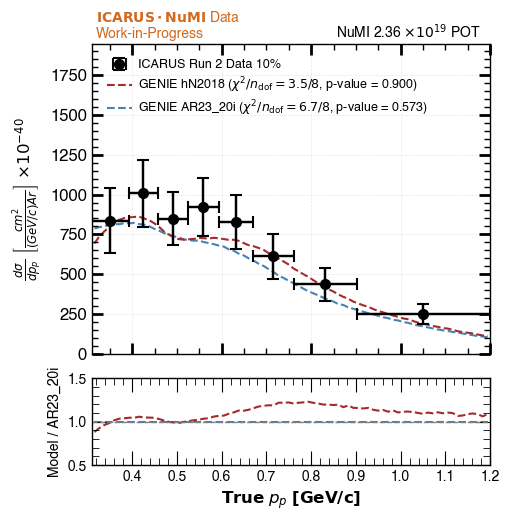

In [9]:
# Overlay GENIE hN2018 with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_hN2018/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_hN2018/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [0.31, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.762, 0.9018, 1.2],
    nuisance_var        = 'ICARUS_1muNp0pi_ProtonP',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE hN2018',
    color               = 'brown',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/proton_momentum/RealData_Containment/XSection', 'proton_momentum_XS_wGENIE_hN2018')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           8.484792e+02
  0.3927 – 0.4571           8.465806e+02
  0.4571 – 0.5239           7.842345e+02
  0.5239 – 0.5934           7.395263e+02
  0.5934 – 0.6689           6.775371e+02
  0.6689 – 0.7620           5.529206e+02
  0.7620 – 0.9018           3.871149e+02
  0.9018 – 1.2000           2.064247e+02

χ² / Ndof = 3.4 / 8 = 0.425
p-value = 0.907


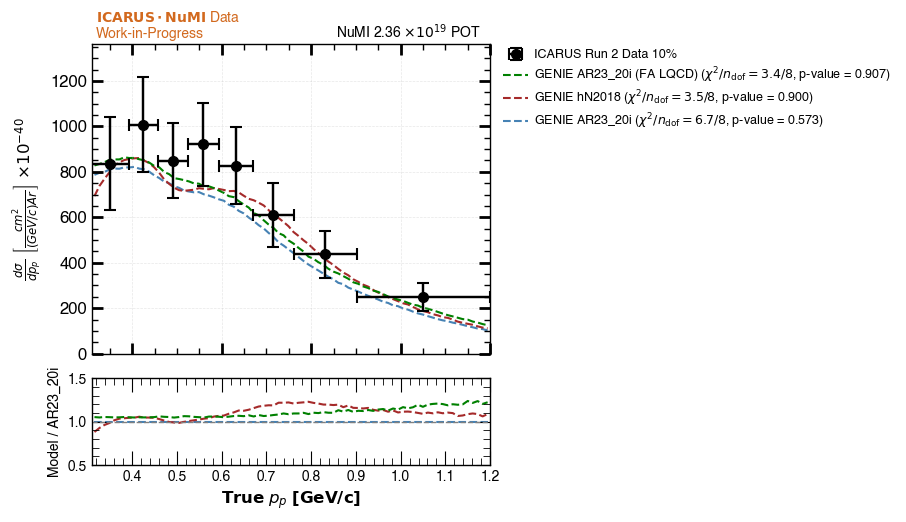

In [10]:
# Overlay GENIE LQCD with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_LQCD/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_LQCD/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [0.31, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.762, 0.9018, 1.2],
    nuisance_var        = 'ICARUS_1muNp0pi_ProtonP',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE AR23_20i (FA LQCD)',
    color               = 'green',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/proton_momentum/RealData_Containment/XSection', 'proton_momentum_XS_wGENIE_LQCD')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           9.333235e+02
  0.3927 – 0.4571           9.298923e+02
  0.4571 – 0.5239           8.600471e+02
  0.5239 – 0.5934           8.145635e+02
  0.5934 – 0.6689           7.419765e+02
  0.6689 – 0.7620           6.096063e+02
  0.7620 – 0.9018           4.336413e+02
  0.9018 – 1.2000           2.353366e+02

χ² / Ndof = 1.0 / 8 = 0.126
p-value = 0.998


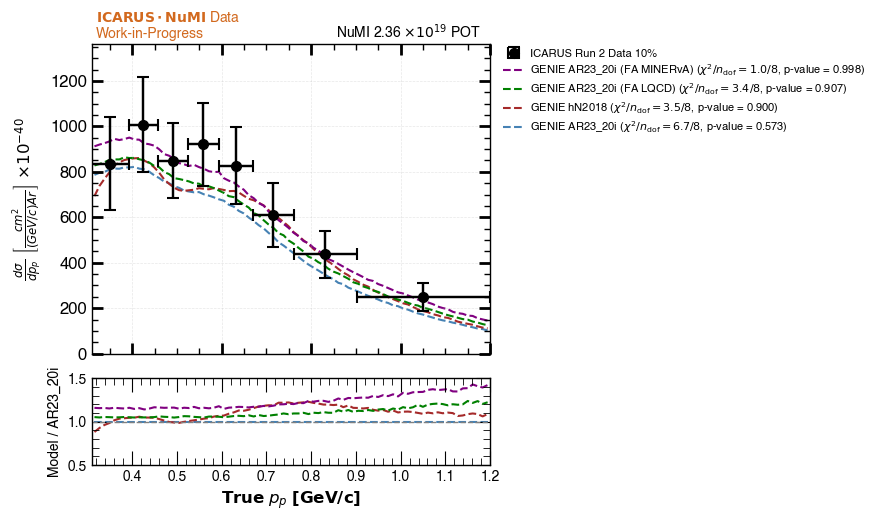

In [11]:
# Overlay GENIE MINERvA with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_MINERvA/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_MINERvA/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [0.31, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.762, 0.9018, 1.2],
    nuisance_var        = 'ICARUS_1muNp0pi_ProtonP',
    scaling_power_of_10 = 1e40,
    label               = 'GENIE AR23_20i (FA MINERvA)',
    color               = 'purple',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/proton_momentum/RealData_Containment/XSection', 'proton_momentum_XS_wGENIE_MINERvA')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           9.002076e+02
  0.3927 – 0.4571           8.955979e+02
  0.4571 – 0.5239           8.667497e+02
  0.5239 – 0.5934           7.939653e+02
  0.5934 – 0.6689           6.446407e+02
  0.6689 – 0.7620           5.127642e+02
  0.7620 – 0.9018           3.664050e+02
  0.9018 – 1.2000           1.817441e+02

χ² / Ndof = 4.2 / 8 = 0.525
p-value = 0.838


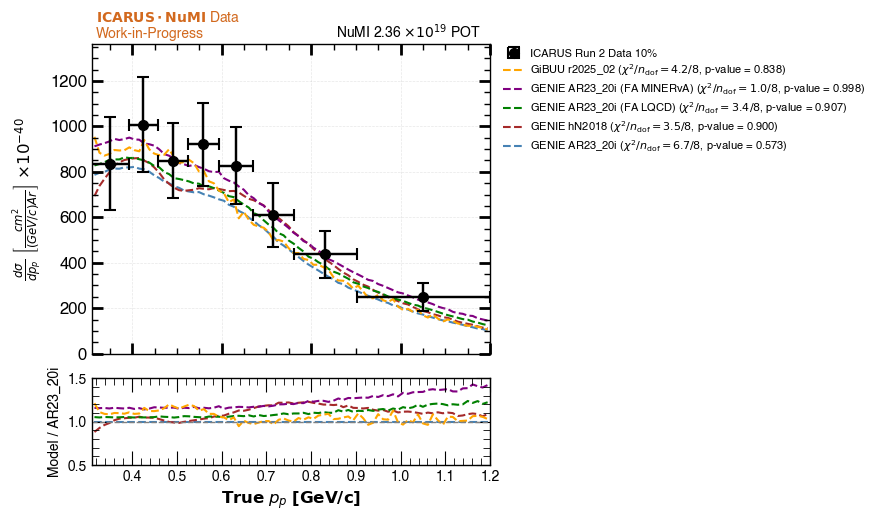

In [12]:
# Overlay GiBUU with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GiBUU/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GiBUU/fhc_Nu-14",
    generator_name      = 'GiBUU',
    bin_edges           = [0.31, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.762, 0.9018, 1.2],
    nuisance_var        = 'ICARUS_1muNp0pi_ProtonP',
    scaling_power_of_10 = 1e40,
    label               = 'GiBUU r2025_02',
    color               = 'orange',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/proton_momentum/RealData_Containment/XSection', 'proton_momentum_XS_wGiBUU')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           5.855399e+02
  0.3927 – 0.4571           6.413491e+02
  0.4571 – 0.5239           6.852544e+02
  0.5239 – 0.5934           6.976808e+02
  0.5934 – 0.6689           6.379437e+02
  0.6689 – 0.7620           5.247894e+02
  0.7620 – 0.9018           3.824165e+02
  0.9018 – 1.2000           2.088452e+02

χ² / Ndof = 9.4 / 8 = 1.176
p-value = 0.309


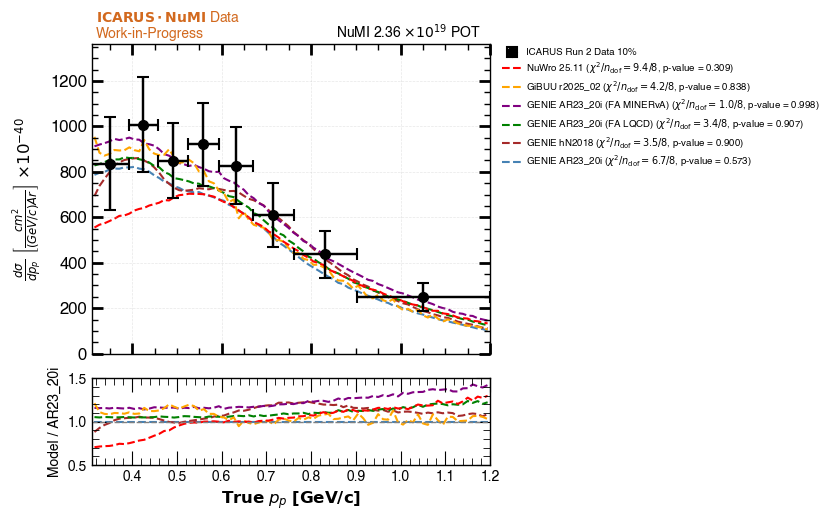

In [13]:
# Overlay NuWro with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NuWro/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NuWro/fhc_Nu-14",
    generator_name      = 'NuWro',
    bin_edges           = [0.31, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.762, 0.9018, 1.2],
    nuisance_var        = 'ICARUS_1muNp0pi_ProtonP',
    scaling_power_of_10 = 1e40,
    label               = 'NuWro 25.11',
    color               = 'red',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/proton_momentum/RealData_Containment/XSection', 'proton_momentum_XS_wNuWro')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           8.660098e+02
  0.3927 – 0.4571           7.975110e+02
  0.4571 – 0.5239           7.735902e+02
  0.5239 – 0.5934           7.424303e+02
  0.5934 – 0.6689           6.553267e+02
  0.6689 – 0.7620           5.185411e+02
  0.7620 – 0.9018           3.554738e+02
  0.9018 – 1.2000           1.762829e+02

χ² / Ndof = 5.7 / 8 = 0.712
p-value = 0.681


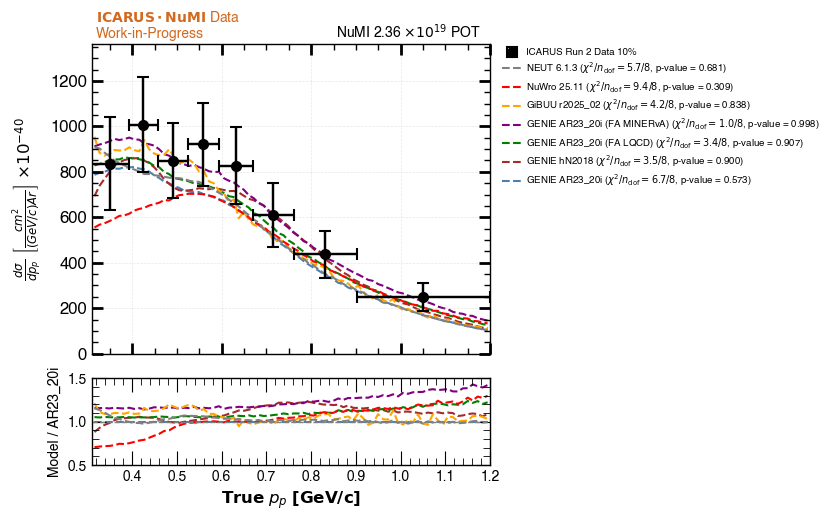

In [14]:
# Overlay NEUT with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NEUT/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NEUT/fhc_Nu-14",
    generator_name      = 'NEUT',
    bin_edges           = [0.31, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.762, 0.9018, 1.2],
    nuisance_var        = 'ICARUS_1muNp0pi_ProtonP',
    scaling_power_of_10 = 1e40,
    label               = 'NEUT 6.1.3',
    color               = 'gray',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/proton_momentum/RealData_Containment/XSection', 'proton_momentum_XS_wNEUT')
display(fig_genie)

## Template Parameter Post-fit Values

One set of 9 template parameters (8 finite bins plus the overflow bin), shared across all four samples -- not split by containment. The overflow parameter is not drawn: `plot_scatter` drops the last bin by default.


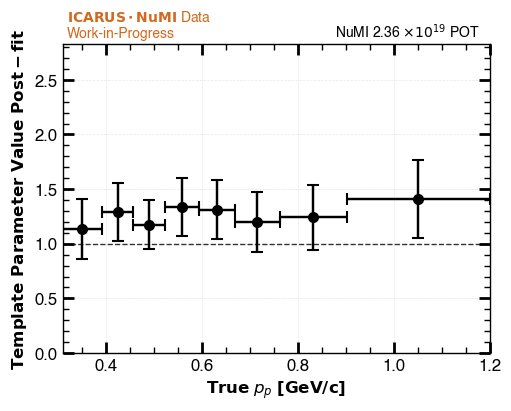

In [15]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
        is_cross_section = False,
        hist_path="FitterEngine/postFit/Hesse/errors/Template Parameter true_leading_proton_momentum/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True}$ $p_{p}$ $\mathbf{[GeV/c]}$',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=[0.31, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.762, 0.9018, 1.2],
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=r'NuMI 2.36 $\times 10^{19}$ POT'
)
save_fig(fig_template, r'../Plots/proton_momentum/RealData_Containment/TemplateParameters', 'proton_momentum')

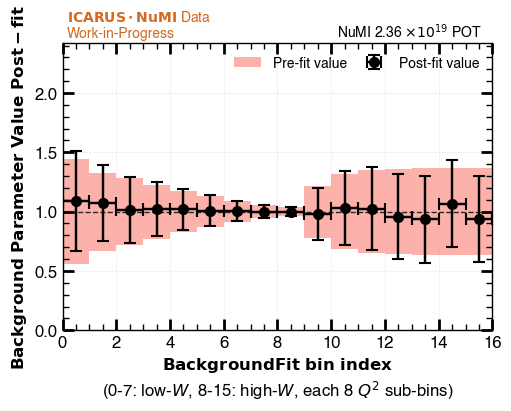

In [16]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=r'NuMI 2.36 $\times 10^{19}$ POT',
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/proton_momentum/RealData_Containment/BackgroundFitParameters', 'proton_momentum')

## Nuisance Parameter Constraints

Interaction-model, flux, and detector systematics -- one set of plots for the whole joint fit, unaffected by the reco-level split.

Number of parameters: 52


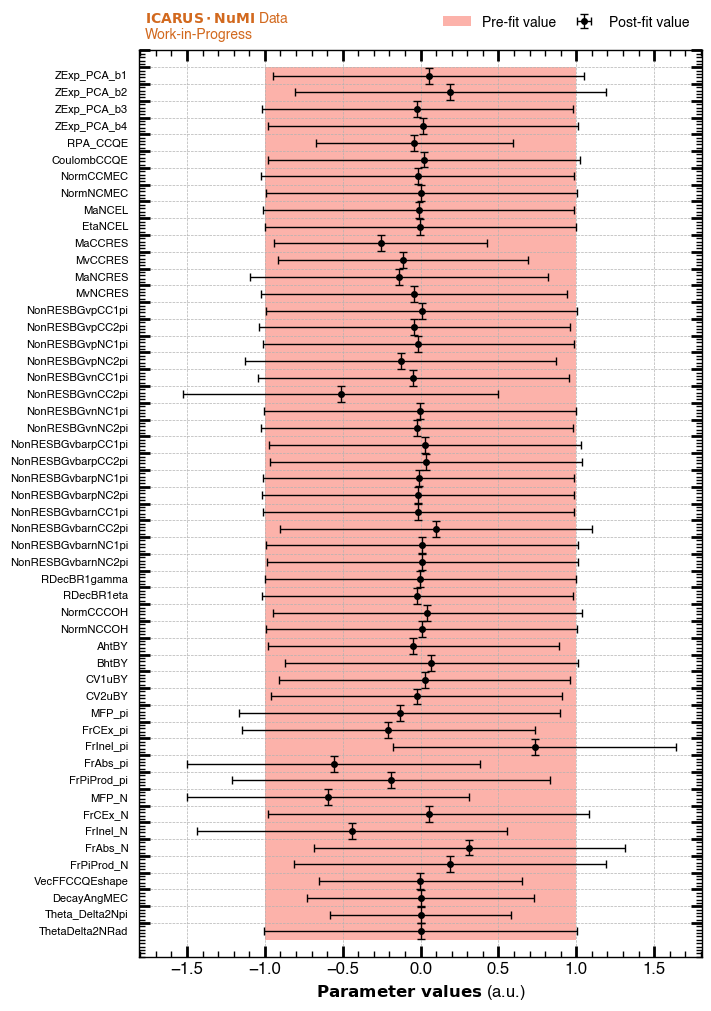

In [17]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root",
    figsize=(7, 10),
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/RealData_Containment/NuisanceParameters', 'proton_momentum_InteractionModel')

Number of parameters: 27


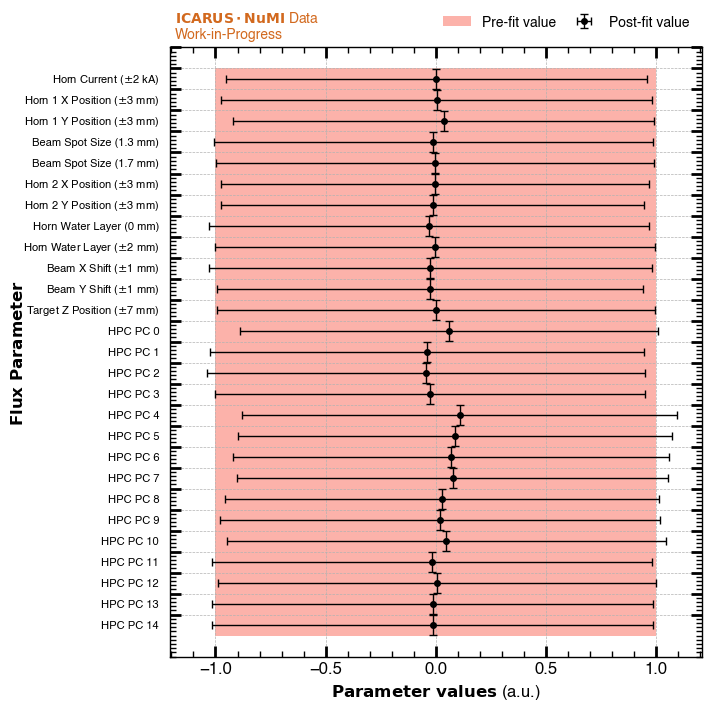

In [18]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/RealData_Containment/NuisanceParameters', 'proton_momentum_Flux')

Number of parameters: 9


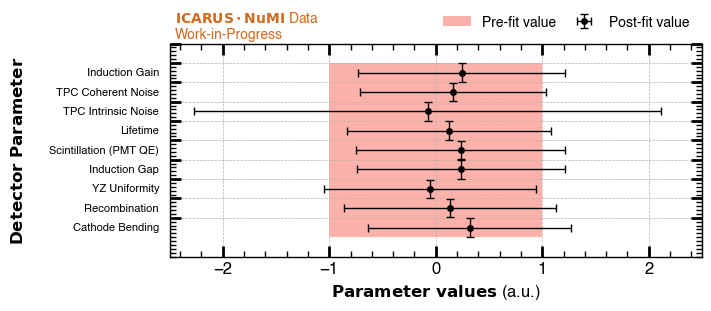

In [19]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root",
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/RealData_Containment/NuisanceParameters', 'proton_momentum_Detector')

Number of parameters: 17


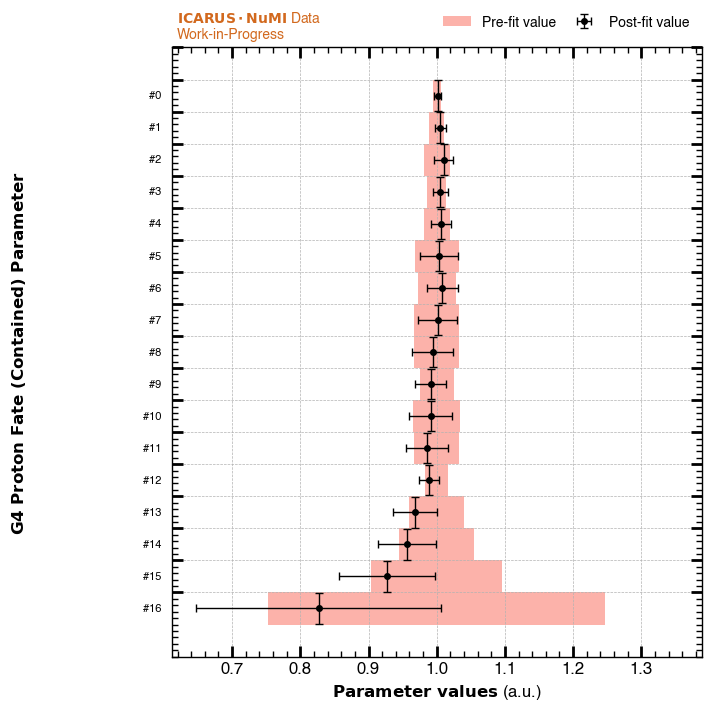

In [20]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (proton momentum, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/RealData_Containment/NuisanceParameters', 'proton_momentum_G4_Proton_Contained')

Number of parameters: 17


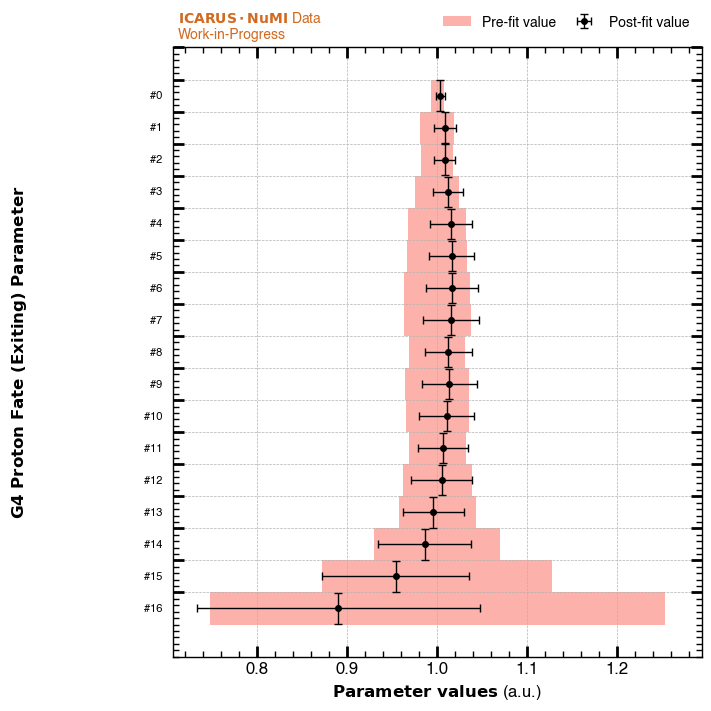

In [21]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (proton momentum, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/RealData_Containment/NuisanceParameters', 'proton_momentum_G4_Proton_Exiting')

Number of parameters: 17


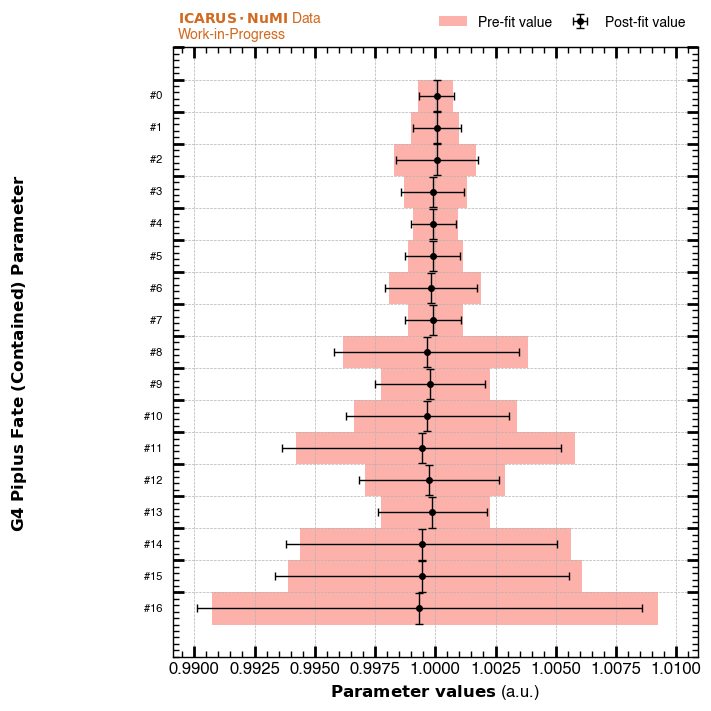

In [22]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (proton momentum, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/RealData_Containment/NuisanceParameters', 'proton_momentum_G4_Piplus_Contained')

Number of parameters: 17


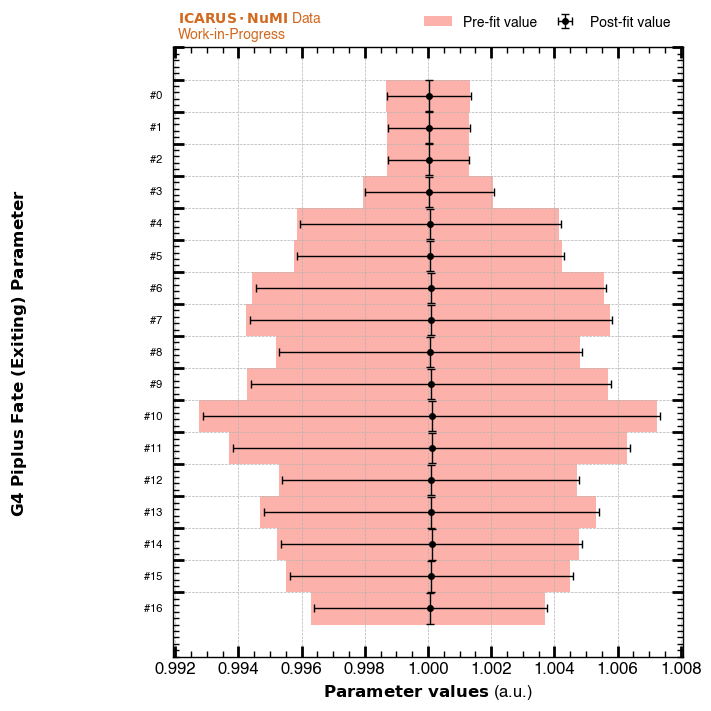

In [23]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (proton momentum, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/RealData_Containment/NuisanceParameters', 'proton_momentum_G4_Piplus_Exiting')

Number of parameters: 17


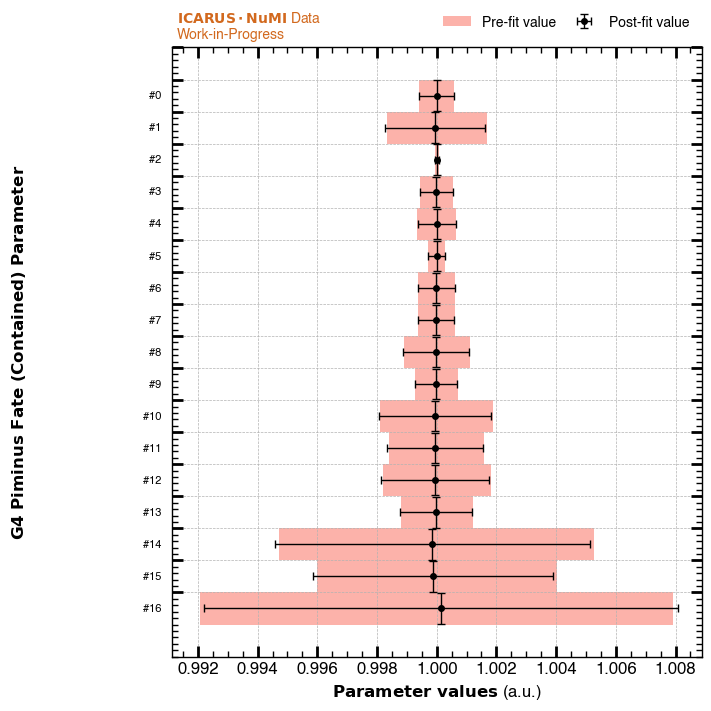

In [24]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (proton momentum, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/RealData_Containment/NuisanceParameters', 'proton_momentum_G4_Piminus_Contained')

Number of parameters: 17


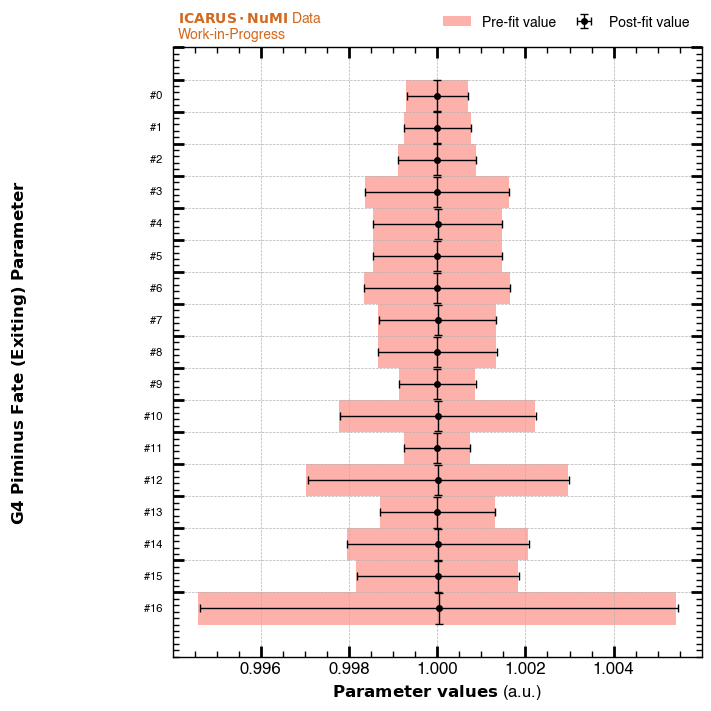

In [25]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (proton momentum, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/RealData_Containment/NuisanceParameters', 'proton_momentum_G4_Piminus_Exiting')

## Covariance / Correlation Matrices

Per-systematic-block matrices -- among the nuisance parameters themselves, not among reco bins, so `bin_range` stays at its default (full block).

Full matrix size: 52×52


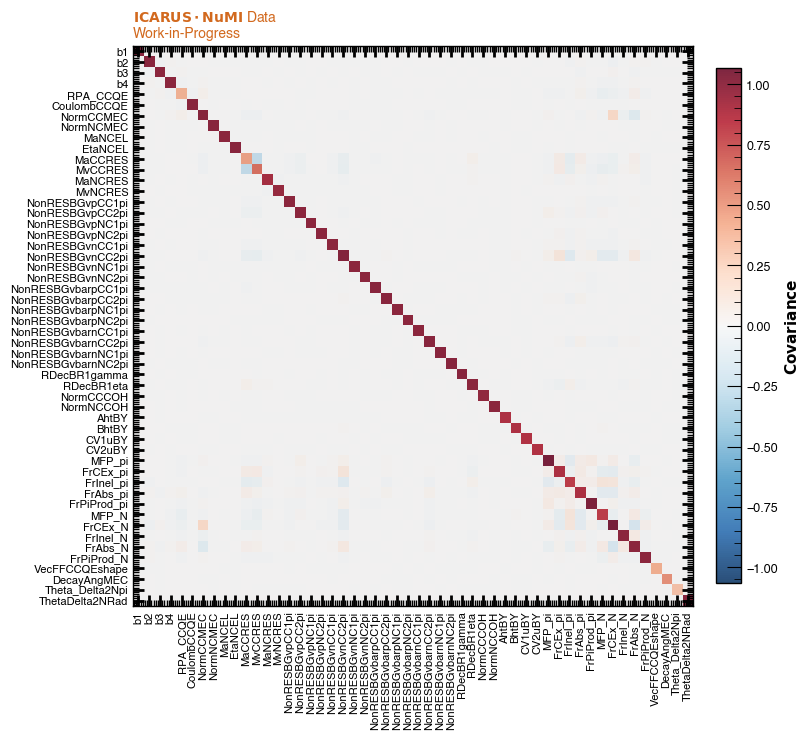

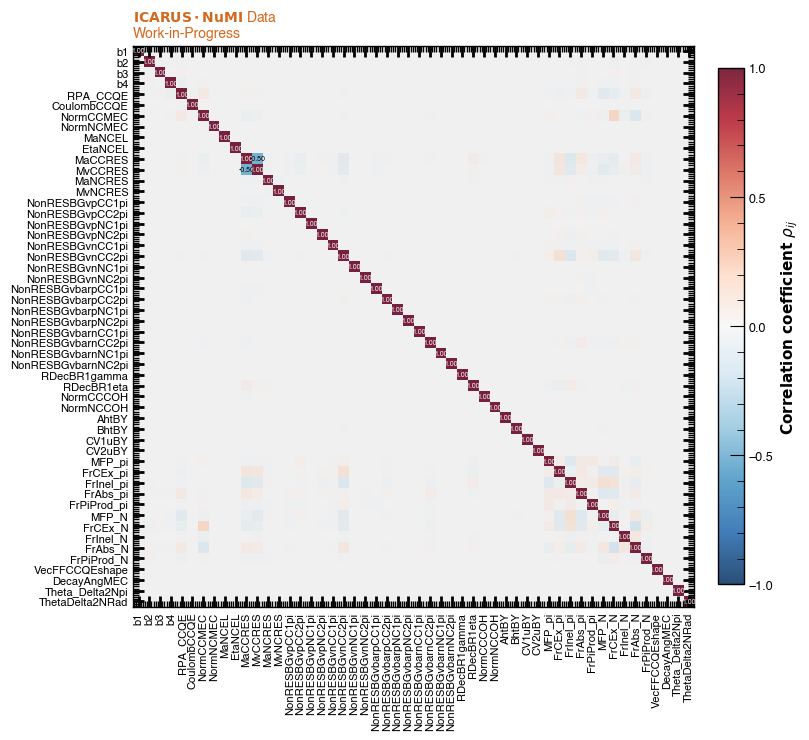

In [26]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(8, 20),
    cov_path  = f"{BASE}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


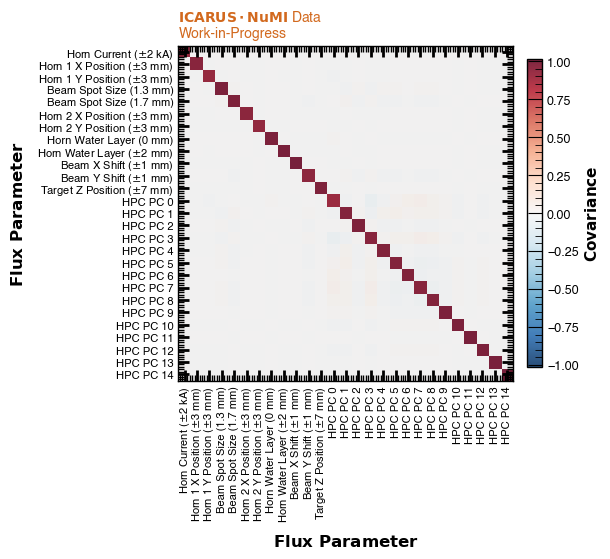

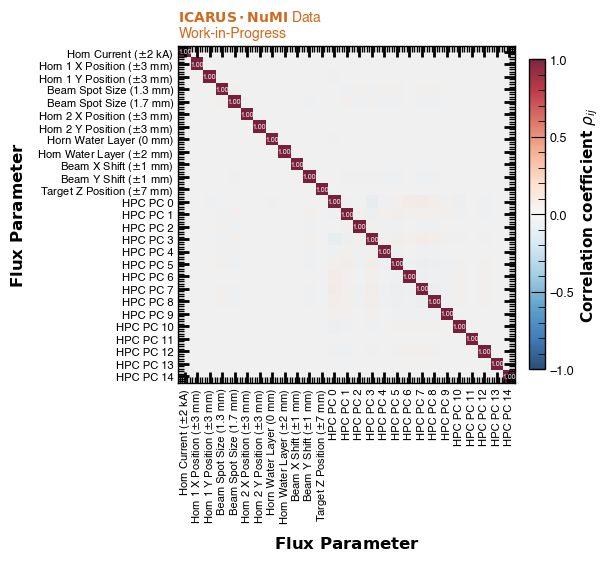

In [27]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


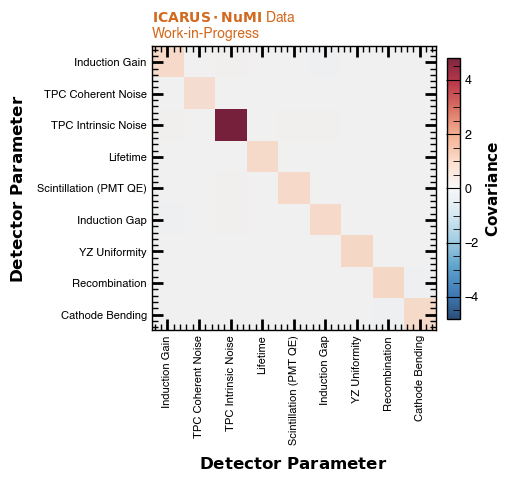

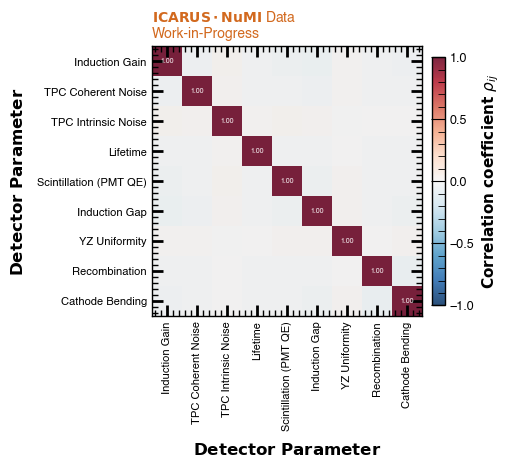

In [28]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'detector_param_correlation')

Full matrix size: 17×17


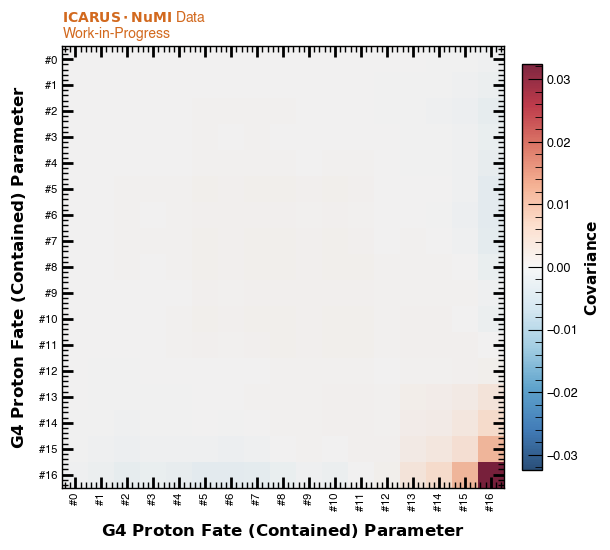

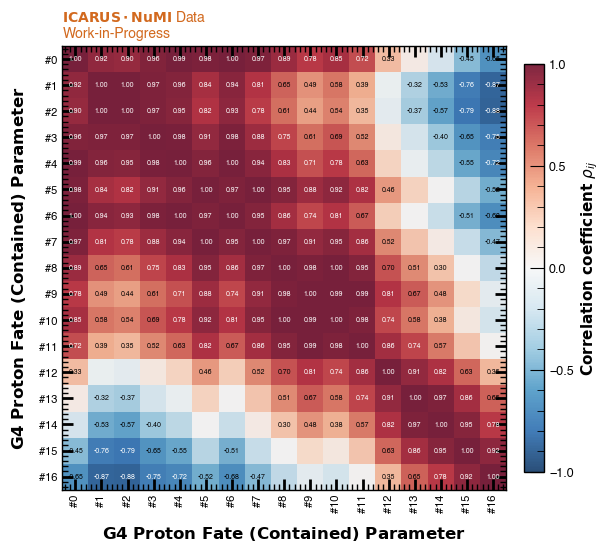

In [29]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (proton momentum, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (proton momentum, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_proton_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_proton_contained_param_correlation')

Full matrix size: 17×17


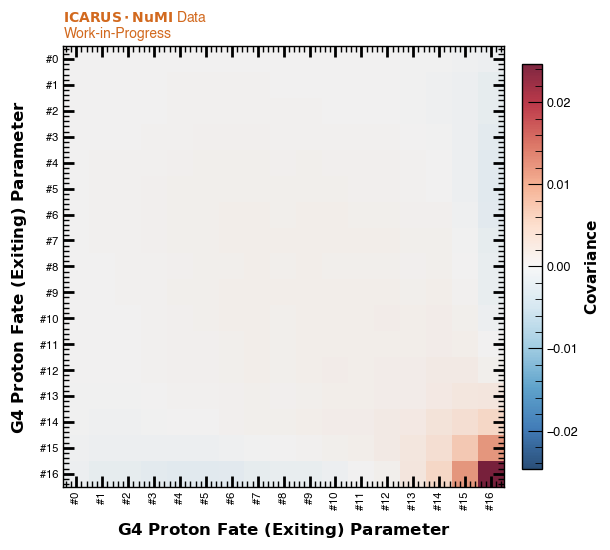

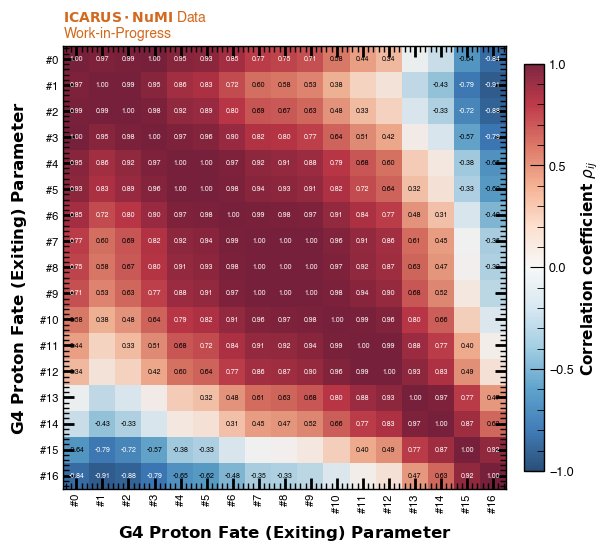

In [30]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (proton momentum, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (proton momentum, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_proton_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_proton_exiting_param_correlation')

Full matrix size: 17×17


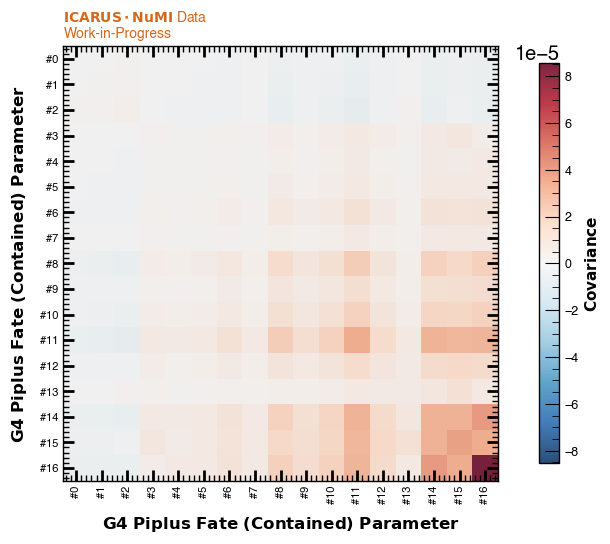

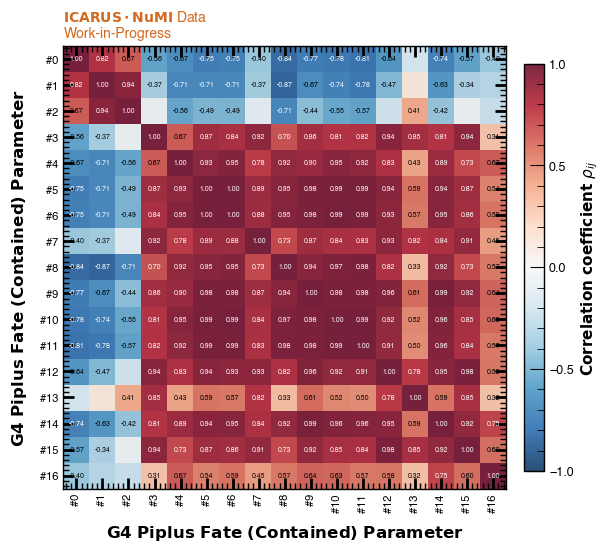

In [31]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (proton momentum, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (proton momentum, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_piplus_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_piplus_contained_param_correlation')

Full matrix size: 17×17


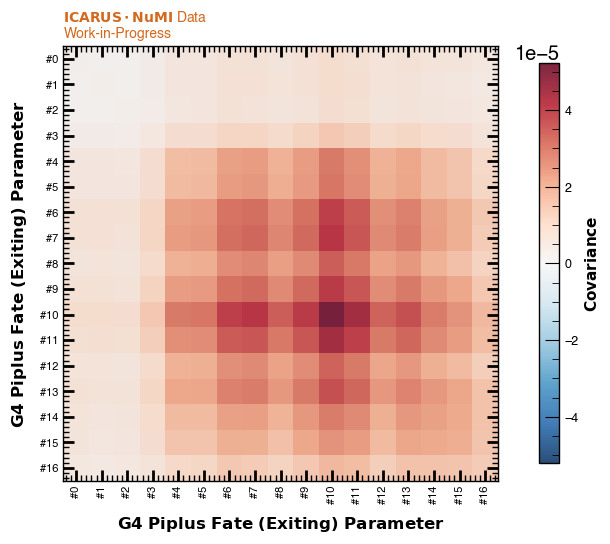

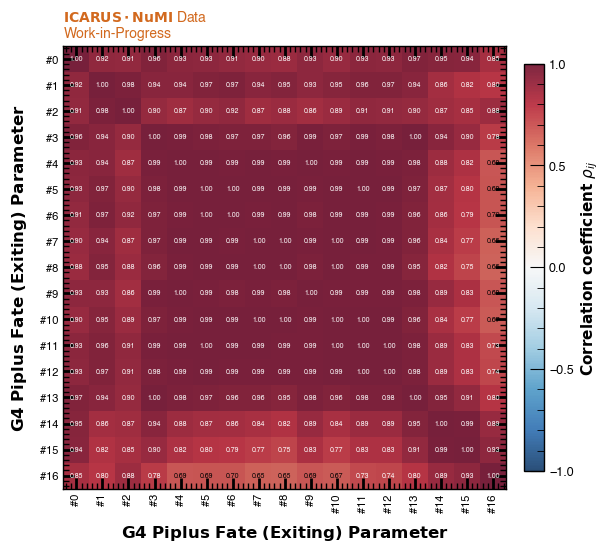

In [32]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (proton momentum, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (proton momentum, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_piplus_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_piplus_exiting_param_correlation')

Full matrix size: 17×17


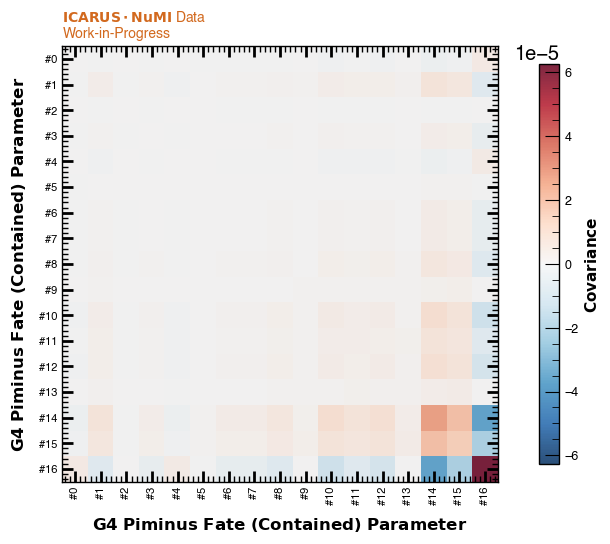

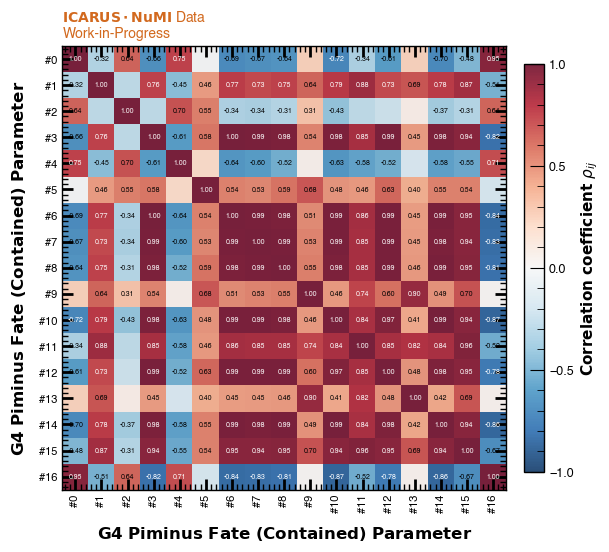

In [33]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (proton momentum, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (proton momentum, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_piminus_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_piminus_contained_param_correlation')

Full matrix size: 17×17


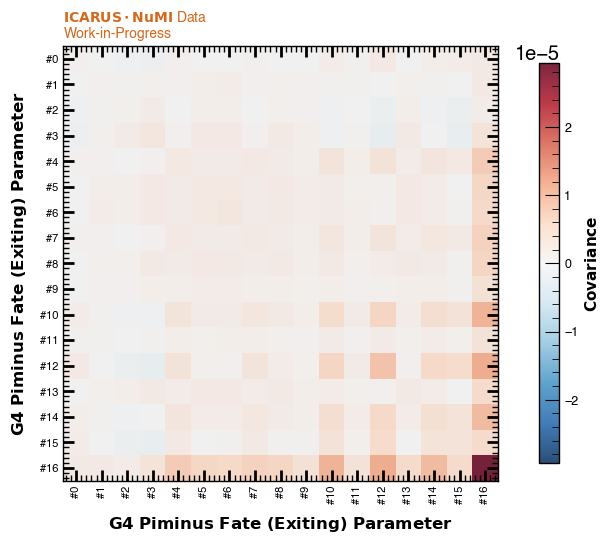

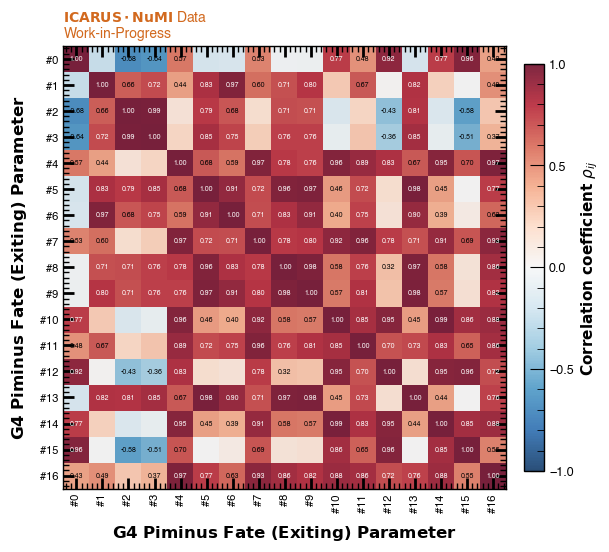

In [34]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (proton momentum, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (proton momentum, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_piminus_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'g4_piminus_exiting_param_correlation')

## Full Covariance / Correlation Matrix (All Systematics + Template Parameters)

Single matrix over every free parameter in the fit -- template, background-fit, cross-section, flux, detector, and all six G4 groups -- read from the fitter's own postfit Hessian block (`FitterEngine/postFit/Hesse/hessian`), not the per-group `errors` blocks the cells above use. `annotate` is left off here since the matrix is too large for per-cell values to be legible.

In [35]:
BASE_ALL = "FitterEngine/postFit/Hesse/hessian"
GROUP_ORDER = [
    "Template Parameter true_leading_proton_momentum",
    "Cross section Systematics",
    "Multisigma Flux Systematics",
    "Detector Systematics",
    "G4 Proton Fate (proton momentum, contained)",
    "G4 Proton Fate (proton momentum, exiting)",
    "G4 Piplus Fate (proton momentum, contained)",
    "G4 Piplus Fate (proton momentum, exiting)",
    "G4 Piminus Fate (proton momentum, contained)",
    "G4 Piminus Fate (proton momentum, exiting)",
    "BackgroundFit true_generator_w binbybin",
]
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/proton_momentum/RealData_Containment/real_containment_proton_momentum.root',
    figsize=(30, 24),
    cov_path  = f"{BASE_ALL}/postfitCovariance_TH2D;1",
    corr_path = f"{BASE_ALL}/postfitCorrelation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=False,
    group_order=GROUP_ORDER,
    show_group_boundaries=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'all_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/proton_momentum/RealData_Containment/Postfits', 'all_param_correlation')

TypeError: plot_both_matrices() got an unexpected keyword argument 'show_group_boundaries'